In [ ]:
import numpy as np
import cupy as cp
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

from scipy.linalg import eigh
from scipy.special import comb 

from itertools import combinations 

import seaborn as sns 

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "text.usetex": False, 
    "font.family": "serif",
    "axes.labelsize": 12,
    "font.size": 12,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

%load_ext autoreload
%autoreload 2

import mylib as ml

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [7]:
def build_matrices(N):

    if N % 2 == 0:
        Gamma_tensor = ml.Dirac_gen_GPU(N).astype(cp.complex64)

        Gamma_5 = Gamma_tensor[0]
        for i in range(N-1):
            Gamma_5 = Gamma_5@Gamma_tensor[i+1]

        diag = cp.diag(Gamma_5)

        if cp.allclose(diag.real, 0):
            mask = (diag.imag > 0)
        else:
            mask = (diag.real >0)

        
        s2 = cp.asarray(list(combinations(range(N), 2)))

        matrices_2 = Gamma_tensor[s2[:, 0]] @ Gamma_tensor[s2[:, 1]]
        matrices_2 = matrices_2[:, mask, :][:,:,mask]
    else:
        Gamma_tensor = ml.Dirac_gen_GPU(N-1).astype(cp.complex64)
        
        Gamma_5 = Gamma_tensor[0]
        for i in range(N-2):
            Gamma_5 = Gamma_5@Gamma_tensor[i+1]
        
        if (N-1) % 4 != 0:
            Gamma_5 = 1j*Gamma_5

        Gamma_5 = 2**(N/2)*Gamma_5 

        Gamma_5 = Gamma_5[None,:,:]
        Gamma_tensor = cp.concatenate((Gamma_tensor,Gamma_5), axis = 0)

        s2 = cp.asarray(list(combinations(range(N), 2)))
        matrices_2 = Gamma_tensor[s2[:, 0]] @ Gamma_tensor[s2[:, 1]]
        

    return matrices_2

def compute_hamil(N, K, N_iterazioni, matrices_2):

    J = 1.0

    sigma_2 = K/(N**(0.5))
    sigma_4 = cp.sqrt(6)* J/(N)**(1.5)


    pairs = int(N*(N-1)/2)
    column_limit = np.zeros(pairs)

    for idx, (i,j) in enumerate(combinations(range(N),2)):
        column_limit[idx] = pairs - int((j+1)*(2*N-j-2)/2)

    column_limit = column_limit.astype(cp.int32)
    max_col = column_limit[0]
    column_limit = cp.asarray(column_limit)
    column_limit = column_limit[:-5]


    couplings_4 = cp.random.normal(loc=0.0, scale=sigma_4, size=(N_iterazioni, pairs-5, max_col), dtype=cp.float32)


    column_indices = cp.arange(max_col)
    mask = column_indices < column_limit[:, None]
    mask = mask[:,::-1]
    final_mat = couplings_4 * mask
    
    couplings_2 = cp.random.normal(loc=0.0, scale=sigma_2, size=(N_iterazioni, matrices_2.shape[0]), dtype=cp.float32)
    hamil_2 = cp.tensordot(couplings_2, matrices_2, axes=([1], [0]))

   
    dim_matrice = matrices_2.shape[1]
    hamil_4 = cp.zeros((N_iterazioni, dim_matrice, dim_matrice), dtype=matrices_2.dtype)

    m2_first = matrices_2[:(pairs-5)]
    m2_last = matrices_2[-max_col:]

    for n in range(N_iterazioni):
        tmp = cp.einsum('pc,cij->pij', final_mat[n], m2_last)
        
        hamil_4[n] = cp.einsum('cij,cjk->ik', tmp, m2_first)
    
    hamil = 1j * hamil_2 + hamil_4
    
    return hamil


def compute_r_index(N, N_iterazioni, hamil):
    #N//2 arrotonda nel caso di N dispari
    
    if N % 2 == 0:
        dim = int(2**(N/2-1))
    else:
        dim = int(2**(N//2))

    energies = cp.empty((N_iterazioni, dim), dtype=cp.float64)
        
    for i in range(N_iterazioni):
        
        energies[i] = cp.linalg.eigvalsh(hamil[i])

   
    lenght = energies.shape[1]
    trim = int(lenght*0.1)
    bulk_energies = energies[:, trim : -trim]
   
    bulk_energies_even = bulk_energies[:, ::2]

    new_spacing = cp.diff(bulk_energies, axis=1)
    new_spacing_even = cp.diff(bulk_energies_even, axis=1)

    r_matrix = new_spacing[:, 1:] / new_spacing[:, :-1]     

    r_index_matrix = cp.minimum(r_matrix, 1/r_matrix)
    r_index_mean = cp.mean(r_index_matrix, axis=1)

    r_prime_matrix = new_spacing_even[:, 1:] / new_spacing_even[:, :-1]  

    r_prime_index_matrix = cp.minimum(r_prime_matrix, 1/r_prime_matrix)
    r_prime_index_mean = cp.mean(r_prime_index_matrix, axis=1)

    r_index_est = cp.mean(r_index_mean)
    sigma_index_est = cp.std(r_index_mean)/cp.sqrt(len(r_index_mean))

    r_prime_index_est = cp.mean(r_prime_index_mean)
    sigma_prime_index_est = cp.std(r_prime_index_mean)/cp.sqrt(len(r_prime_index_mean))

    return r_index_est, sigma_index_est, r_prime_index_est, sigma_prime_index_est


In [8]:
N = 15
N_iterazioni = 40
Ndots = 35

K_values = cp.logspace(-8, 8, num=Ndots, base=cp.e, dtype=cp.float64)

matrices_2 = build_matrices(N)

r_index_est = cp.zeros(Ndots)
sigma_index_est = cp.zeros(Ndots)

r_prime_index_est = cp.zeros(Ndots)
sigma_prime_index_est = cp.zeros(Ndots)

for i in range(Ndots):
  hamil = compute_hamil(N, K_values[i], N_iterazioni, matrices_2)
    
  r_index_est[i], sigma_index_est[i], r_prime_index_est[i], sigma_prime_index_est[i] = compute_r_index(N, N_iterazioni, hamil)


r_index_est = r_index_est.get()
sigma_index_est = sigma_index_est.get()
r_prime_index_est = r_prime_index_est.get()
sigma_prime_index_est = sigma_prime_index_est.get()

K_values = K_values.get()


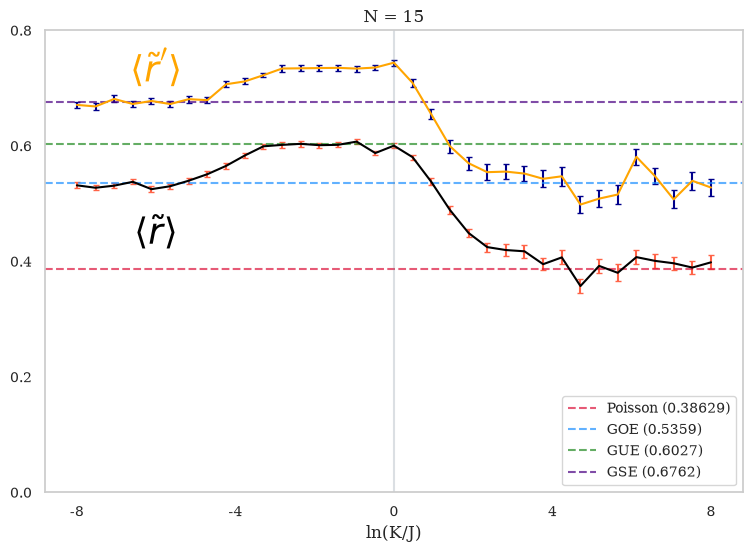

In [9]:


plt.figure(figsize=(9, 6))


plt.errorbar(
    K_values, 
    r_index_est, 
    yerr=sigma_index_est,       
    marker='',            
    linestyle='-',         
    color='black',           
    ecolor='tomato',         
    elinewidth=1.5,          
    capsize=2,               
    markersize=5
)

plt.errorbar(
    K_values, 
    r_prime_index_est, 
    yerr=sigma_prime_index_est,           
    marker='',             
    linestyle='-',           
    color='orange',            
    ecolor='darkblue',         
    elinewidth=1.5,         
    capsize=2,               
    markersize=5
)

plt.axhline(y=0.38629, color='crimson', linestyle='--', alpha=0.7, label='Poisson (0.38629)')
plt.axhline(y=0.5359, color='dodgerblue', linestyle='--', alpha=0.7, label='GOE (0.5359)')
plt.axhline(y=0.6027, color='forestgreen', linestyle='--', alpha=0.7, label='GUE (0.6027)')
plt.axhline(y=0.6762, color='indigo', linestyle='--', alpha=0.7, label='GSE (0.6762)')
plt.axvline(x=1, color='slategrey', linestyle='-', alpha=0.25)


plt.xscale('log', base = np.e) 

esponenti_voluti = [-8, -4, 0, 4, 8] 

posizioni_ticks = np.exp(esponenti_voluti)


plt.xticks(posizioni_ticks)

def formatta_esponente(x, pos):
    esponente = np.log(x)
   
    return f"{int(np.round(esponente))}"


plt.gca().xaxis.set_major_formatter(ticker.FuncFormatter(formatta_esponente))

yticks = [0, 0.2, 0.4, 0.6, 0.8]

plt.yticks(yticks)

plt.text(np.exp(-6), 0.43, fr'$\langle \tilde r \rangle$', color='black', fontsize=26, ha='center')
plt.text(np.exp(-6), 0.71, fr'$\langle \tilde r^\prime \rangle$', color='orange', fontsize=26, ha='center')


plt.xlabel(r'ln(K/J)')

plt.title(f'N = {N}')

plt.grid(False, axis='y')

plt.grid(False, axis = "x")

plt.ylim(0,0.8)

plt.legend(loc='lower right', fontsize=10)

plt.show()